# Raredon

In [1]:
import sys 
import os
import shutil

# Data analysis & stats
import pandas as pd
import numpy as np
from scipy.stats import ranksums
from scipy.sparse import csr_matrix
from scipy.stats import ttest_ind
from scipy import sparse


from sklearn.preprocessing import MinMaxScaler, RobustScaler



# Single-cell
import scanpy as sc
import scanpy.external as sce
import anndata
# Cell type annotation
sys.path.append('../../scoreCT/src/')
import scorect_api as ct
import scallop as sl


# Plotting & palettes
import matplotlib.pyplot as plt
import seaborn as sns
from palettable.cartocolors.qualitative import Pastel_10, Safe_10, Bold_10, Vivid_10, Prism_10, Antique_5
from palettable.colorbrewer.qualitative import Set3_12

sys.path.append('../../')
from stacked_barplots import plot_stacked_bar

sys.path.append('/media/amon/2TB-HD/Olga/Aging_and_transcriptional_noise/tools')
import transcriptional_noise as tn

seed=10

In [2]:
bold_and_vivid = Bold_10.hex_colors + Vivid_10.hex_colors + Pastel_10.hex_colors

# Load and preprocessing

In [7]:
# # put each dataset in a separate directory:
# for fname in [fname for fname in os.listdir('../data/raw_data/raredon/') if (fname.startswith('GSM') and len(fname) > 3)]:
#     gsm = fname.split('_')[0]
#     if not os.path.isdir(f'../data/raw_data/raredon/GSM/{gsm}/'): 
#         os.mkdir(f'../data/raw_data/raredon/GSM/{gsm}')
#     if fname.endswith('barcodes.tsv.gz'):
#         new_fname = 'barcodes.tsv.gz'
#     elif fname.endswith('genes.tsv.gz'):
#         new_fname = 'features.tsv.gz'
#     elif fname.endswith('mtx.gz'): 
#         new_fname = 'matrix.mtx.gz'

#     shutil.move(f'../data/raw_data/raredon/{fname}', f'../data/raw_data/raredon/GSM/{gsm}/{new_fname}')

In [8]:
gsm_list = [fname.split('_')[0] for fname in os.listdir('../../data/raw_data/raredon/GSM')]

In [9]:
def create_annData(gsm): 
    adata = sc.read_mtx(f'../data/raw_data/raredon/GSM/{gsm}/matrix.mtx.gz').transpose()
    barcodes = pd.read_csv(f'../data/raw_data/raredon/GSM/{gsm}/barcodes.tsv.gz', sep='\t', index_col=0).set_index('x')
    genes = pd.read_csv(f'../data/raw_data/raredon/GSM/{gsm}/features.tsv.gz', sep='\t', index_col=0).set_index('x')
    adata.var = genes
    adata.obs = barcodes
    return adata

In [8]:
human_gsm = ['GSM3926545', 'GSM3926546', 'GSM4050097', 'GSM4050099', 'GSM4050101', 'GSM4050103', 'GSM4050105', 'GSM4050107', 'GSM4050109', 'GSM4050111', 'GSM4050112', 'GSM4050113', 'GSM4050114', 'GSM4050115'] 
batch_dic = {str(i): gsm for i, gsm in enumerate(human_gsm)}
# gsm = [batch_dic[batch] for batch in adata.obs['batch']]

In [9]:
adata_human = [create_annData(gsm) for gsm in human_gsm]

In [10]:
adata = sc.AnnData.concatenate(*adata_human, batch_categories=human_gsm)

In [ ]:
adata_human = None

In [31]:
metadata = pd.read_csv('../data/raw_data/raredon/metadata.csv', sep=',', index_col=0)
metadata = metadata[metadata.organism == 'Homo sapiens']
adata.obs['sex'] = [metadata.loc[gsm, 'sex'] for gsm in adata.obs['batch']]
adata.obs['age'] = [metadata.loc[gsm, 'age'] for gsm in adata.obs['batch']]

In [15]:
sc.pp.normalize_total(adata, target_sum=1e4)

In [16]:
sc.pp.log1p(adata)

In [19]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=4, min_disp=0.5)

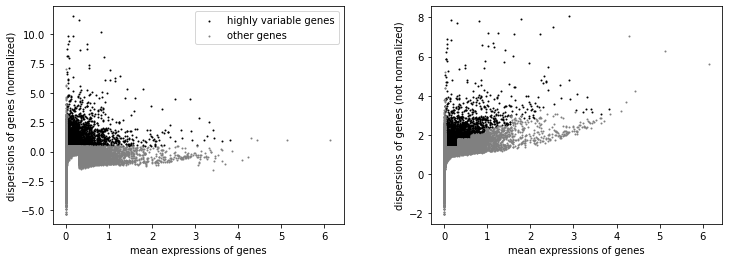

In [20]:
sc.pl.highly_variable_genes(adata)

In [21]:
sc.pp.pca(adata)

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'sex' as categorical


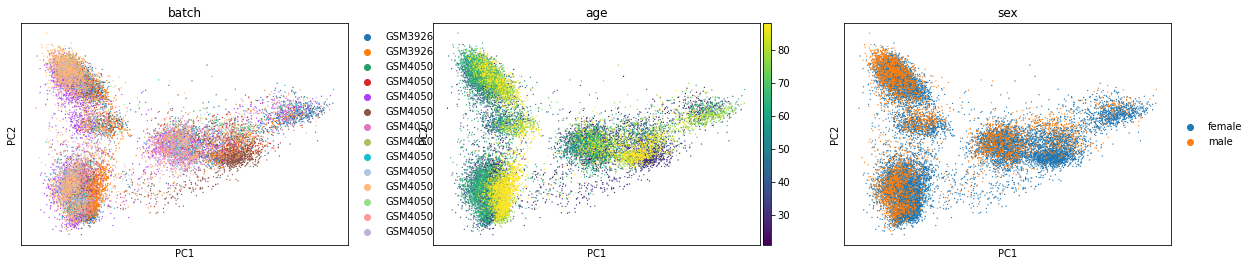

In [32]:
sc.pl.pca(adata, color=['batch', 'age', 'sex'])

In [36]:
sce.pp.harmony_integrate(adata, key='batch')

2021-09-21 16:52:11,937 - harmonypy - INFO - Iteration 1 of 10
2021-09-21 16:52:27,600 - harmonypy - INFO - Iteration 2 of 10
2021-09-21 16:52:44,244 - harmonypy - INFO - Iteration 3 of 10
2021-09-21 16:52:59,470 - harmonypy - INFO - Iteration 4 of 10
2021-09-21 16:53:14,854 - harmonypy - INFO - Iteration 5 of 10
2021-09-21 16:53:30,609 - harmonypy - INFO - Converged after 5 iterations


In [37]:
sc.pp.neighbors(adata, use_rep='X_pca_harmony')

In [38]:
sc.tl.umap(adata)

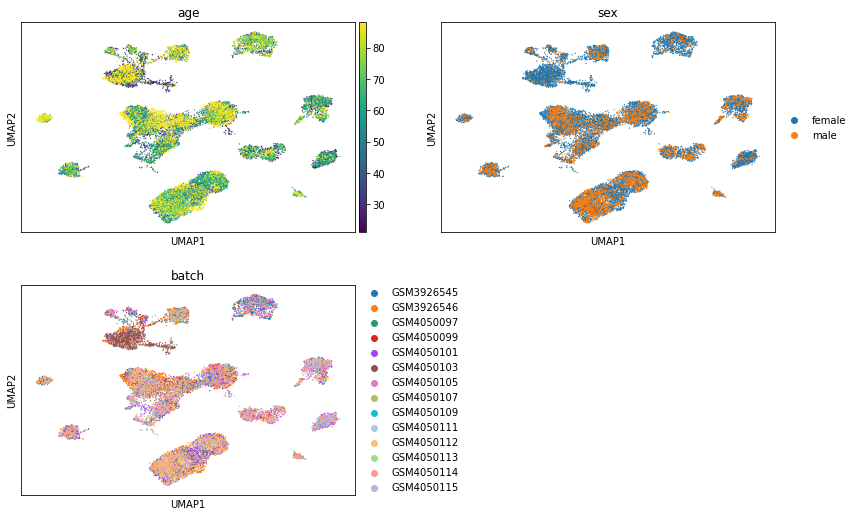

In [67]:
sc.pl.umap(adata, color=['age', 'sex', 'batch'], ncols=2)

# Cell type annotation
We use the annotation from the human lung atlas. 

In [74]:
ref_marker = pd.read_csv('../output/tables/Human_lung_atlas_markers.csv', index_col=0).iloc[0:500, :]

In [75]:
ref_marker

,Adventitial Fibroblast,Alveolar Fibroblast,B cell,Basophil/Mast 1,Basophil/Mast 2,Bronchial Vessel 1,Bronchial Vessel 2,CD1c-positive myeloid dendritic cell,Capillary Aerocyte,Capillary Intermediate 1,...,pericyte cell,plasma cell,"plasmacytoid dendritic cell, human",pulmonary ionocyte,respiratory basal cell,tracheobronchial serous cell,type I pneumocyte,type II pneumocyte,vascular associated smooth muscle cell,vein endothelial cell
0,C1S,RARRES2,CD79A,TPSAB1,TPSAB1,SPARCL1,SOCS3,HLA-DPB1,EDNRB,HLA-E,...,CALD1,SSR4,ITM2C,EPCAM,MPZL2,EHF,AGER,SFTPB,SOD3,PRSS23
1,LUM,MFAP4,CD79B,MS4A2,TPSB2,GNG11,ESAM,RPS24,HLA-E,CLDN5,...,COX4I2,SPCS2,IRF7,PPDPF,LAMB3,WFDC2,EMP2,SFTPC,CALD1,VWF
2,COL6A2,DCN,RPS27,TPSB2,HPGDS,EMCN,TM4SF1,RPL26,HPGD,CNN3,...,PDGFRB,SEC11C,SERPINF1,KRT8,TSC22D1,PPP1R1B,LMO7,SFTA2,BGN,RAMP3
3,LTBP4,LUM,CD37,CPA3,MS4A2,CLEC14A,SPARCL1,RPS23,RAMP2,RAMP2,...,NDUFA4L2,JCHAIN,LILRA4,ATP1A1,SERPINF1,CD24,CAV1,SFTPA1,TAGLN,SRPX
4,RARRES2,PMP22,PTPRCAP,HPGDS,LMNA,IFITM3,GNG11,RPS2,AQP1,IFITM3,...,HIGD1B,TSC22D3,RPS3A,ASCL3,PERP,LTF,CYP4B1,MUC1,MYL9,SLCO2A1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,MYL9,PCDH15,RPS6KA5,FBXL3,HBP1,LYRM1,ETV6,ST14,STC1,YBX3,...,TANC1,HERC2P7,DCPS,DEGS2,CUTA,NCSTN,GALNT5,BCAT2,SSBP2,BHMT2
496,RAB3IL1,EFS,DANCR,HOMER3,GALNT3,LDLR,CYTH2,TOB1,HID1-AS1,IRF1-AS1,...,CACNA2D1,KLHL6,C17orf49,SRARP,PIM3,TMEM99,RCAN1,ATP2C2,AGAP2-AS1,CCDC69
497,PRRX2,NEGR1,CBFA2T3,KRT222,RGPD1,IL3RA,MLKL,PER1,HLA-B,HMBOX1,...,CRIP2,SEPTIN1,PREX1,SORL1,SRPK1,UXT,MYO1D,BZW2,ANO1,MAP3K11
498,FAT4,ANGPTL4,PPP1R3E,ITGA9,IDI1,KCTD12,ZNF281,DDIT4,LOC729970,LSR,...,C9orf153,SEC63,PIK3CD,DUSP4,RPL28,CD59,UNC13B,FIS1,COL8A1,CCM2L


In [81]:
sc.tl.leiden(adata, resolution=3)

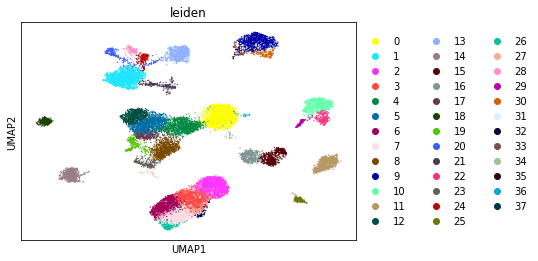

In [82]:
sc.pl.umap(adata, color='leiden')

In [84]:
sc.tl.rank_genes_groups(adata, groupby='leiden')

/home/amon/anaconda3/lib/python3.7/site-packages/scanpy/tools/_rank_genes_groups.py:394: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider using pd.concat instead.  To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'names'] = self.var_names[global_indices]
/home/amon/anaconda3/lib/python3.7/site-packages/scanpy/tools/_rank_genes_groups.py:396: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider using pd.concat instead.  To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'scores'] = scores[global_indices]
/home/amon/anaconda3/lib/python3.7/site-packages/scanpy/tools/_rank_genes_groups.py:399: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, whic

In [85]:
marker_df = ct.wrangle_ranks_from_anndata(adata)

Wrangling: Number of markers used in ranked_gene_groups:  46204
Wrangling: Groups used for ranking: leiden


In [86]:
# Score cell types for each cluster 
# Let's set parameters first - K represents the number of genes included in the ranking
# m represents the number of bins used to divide the top K genes.
K = 300
m = 5
# Get the background genes - here, all the genes used to run the differential gene expression test
background = adata.var_names.tolist()
# Now run the function
ct_pval, ct_score = ct.celltype_scores(nb_bins=m,
                                        ranked_genes=marker_df,
                                        K_top = K,
                                        marker_ref=ref_marker,
                                        background_genes=background)

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'cell_type' as categorical


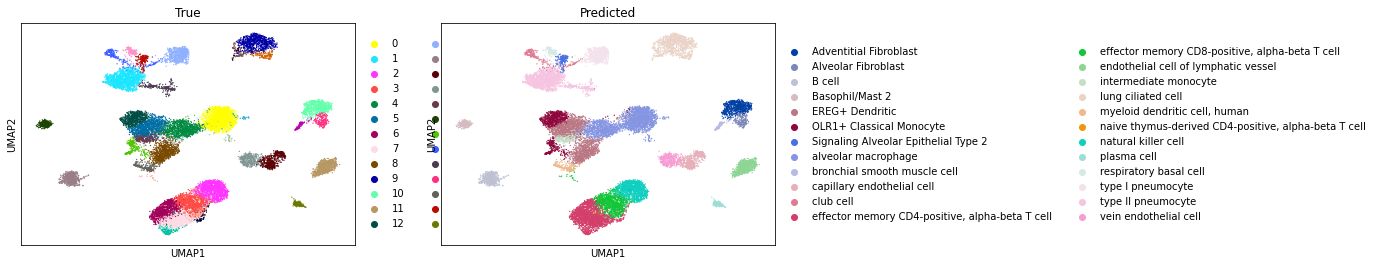

In [87]:
# Now assign clusters to cell types
cluster_assign = adata.obs['leiden']
celltype_assign = ct.assign_celltypes(cluster_assignment=cluster_assign, ct_pval_df=ct_pval, ct_score_df=ct_score, cutoff=0.1)
# Add to anndata object
adata.obs['cell_type'] = celltype_assign
# Let's compare with the true assignment now! 
sc.pl.umap(adata, color=['leiden','cell_type'], title=['True','Predicted'], cmap='Set2')

In [92]:
adata.write('../data/anndatas/annotated/Raredon2019.h5ad')

# Start from annotated dataset

In [3]:
adata = sc.read('../../data/anndatas/annotated/Raredon2019.h5ad')

In [4]:
len(set(adata.obs['cell_type']))

24

In [5]:
for gsm in set(adata.obs['batch']): 
    print(gsm, adata[adata.obs['batch'] == gsm].shape[0], adata[adata.obs['batch'] == gsm].obs['age'][0],  adata[adata.obs['batch'] == gsm].obs['sex'][0])

GSM3926545 2193 76.0 female
GSM4050099 583 35.0 male
GSM4050103 2074 32.0 female
GSM4050112 2825 65.0 male
GSM4050115 363 48.0 female
GSM4050109 574 64.0 male
GSM4050111 823 62.0 female
GSM4050114 502 61.0 male
GSM4050097 466 22.0 male
GSM4050105 1291 21.0 female
GSM3926546 2997 88.0 female
GSM4050107 211 54.0 male
GSM4050101 2849 41.0 female
GSM4050113 116 50.0 male


* GSM3926546 2997 88.0 female
* GSM3926545 2193 76.0 female
* GSM4050112 2825 65.0 male

* GSM4050103 2074 32.0 female
* GSM4050101 2849 41.0 female

-----------------------------
* GSM4050113 116 50.0 male
* GSM4050107 211 54.0 male
* GSM4050114 502 61.0 male
* GSM4050111 823 62.0 female
* GSM4050115 363 48.0 female

In [6]:
# GSM4050097 466 22.0 male
# GSM4050099 583 35.0 male
# GSM4050105 1291 21.0 female
# GSM4050103 2074 32.0 female
# GSM4050101 2849 41.0 female

# GSM4050109 574 64.0 male
# GSM4050112 2825 65.0 male
# GSM3926545 2193 76.0 female
# GSM3926546 2997 88.0 female

In [7]:
selected = ['GSM4050097', 'GSM4050099', 'GSM4050105', 'GSM4050103', 'GSM4050101', 'GSM4050109', 'GSM4050112','GSM3926545', 'GSM3926546']

In [8]:
adata = adata[adata.obs['batch'].isin(selected),:]

In [9]:
set(adata.obs['age'])

{21.0, 22.0, 32.0, 35.0, 41.0, 64.0, 65.0, 76.0, 88.0}

In [10]:
tn.rerun_preprocessing(adata, batch_key='batch')

Trying to set attribute `.var` of view, copying.
2021-11-09 14:10:13,276 - harmonypy - INFO - Iteration 1 of 10

2021-11-09 14:10:13,276 - scallop / harmonypy - INFO - Iteration 1 of 10
2021-11-09 14:10:22,238 - harmonypy - INFO - Iteration 2 of 10

2021-11-09 14:10:22,238 - scallop / harmonypy - INFO - Iteration 2 of 10
2021-11-09 14:10:31,444 - harmonypy - INFO - Iteration 3 of 10

2021-11-09 14:10:31,444 - scallop / harmonypy - INFO - Iteration 3 of 10
2021-11-09 14:10:40,386 - harmonypy - INFO - Iteration 4 of 10

2021-11-09 14:10:40,386 - scallop / harmonypy - INFO - Iteration 4 of 10
2021-11-09 14:10:50,430 - harmonypy - INFO - Iteration 5 of 10

2021-11-09 14:10:50,430 - scallop / harmonypy - INFO - Iteration 5 of 10
2021-11-09 14:11:01,534 - harmonypy - INFO - Converged after 5 iterations

2021-11-09 14:11:01,534 - scallop / harmonypy - INFO - Converged after 5 iterations


AnnData object with n_obs × n_vars = 15852 × 30832
    obs: 'batch', 'sex', 'age', 'leiden', 'cell_type'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'n_cells'
    uns: 'batch_colors', 'cell_type_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'sex_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [11]:
adata

AnnData object with n_obs × n_vars = 15852 × 30832
    obs: 'batch', 'sex', 'age', 'leiden', 'cell_type'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'n_cells'
    uns: 'batch_colors', 'cell_type_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'sex_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

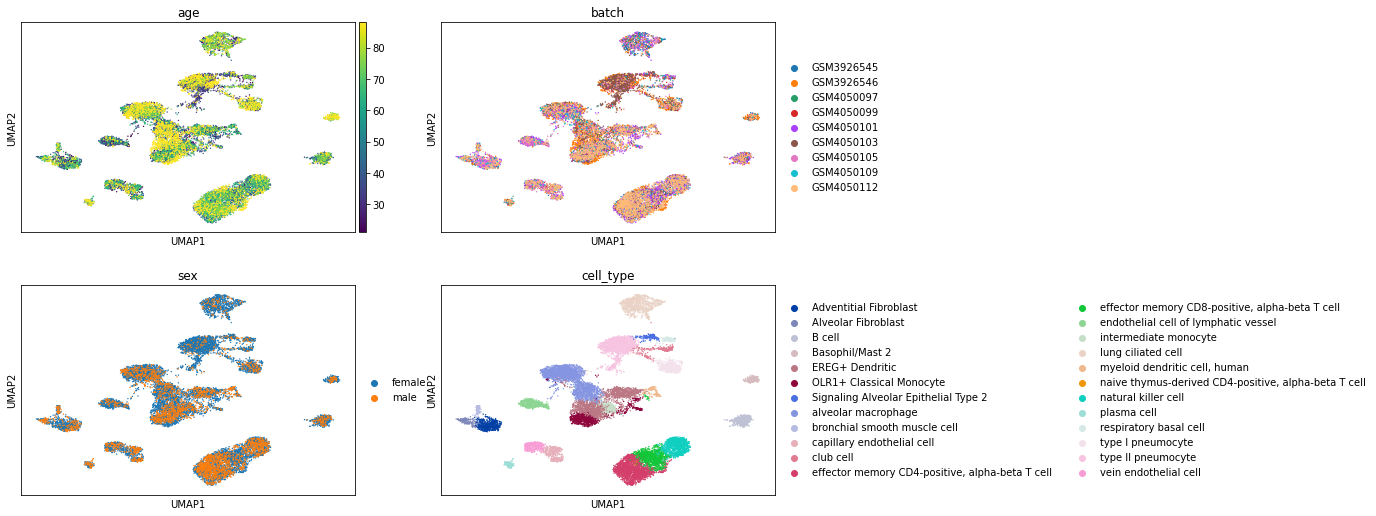

In [12]:
sc.pl.umap(adata, color=['age', 'batch', 'sex', 'cell_type'], ncols=2)

In [13]:
adata.obs['age_number'] = adata.obs['age']

In [14]:
adata.obs['age'] = ['Young' if int(age) < 50 else 'Old' for age in adata.obs['age_number']]

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'age' as categorical


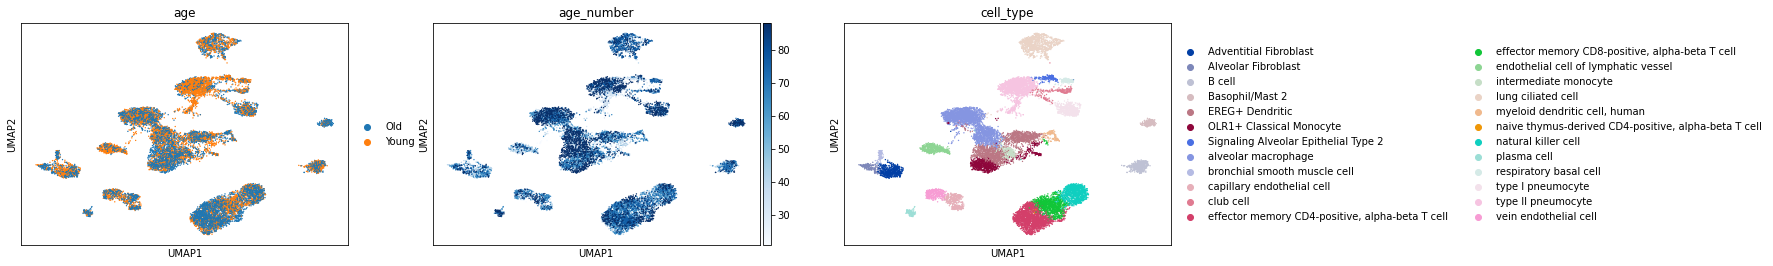

In [15]:
sc.pl.umap(adata, color=['age', 'age_number', 'cell_type'], cmap='Blues')

In [16]:
adata

AnnData object with n_obs × n_vars = 15852 × 30832
    obs: 'batch', 'sex', 'age', 'leiden', 'cell_type', 'age_number'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'n_cells'
    uns: 'batch_colors', 'cell_type_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'sex_colors', 'umap', 'age_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [17]:
set(adata[adata.obs['age'] == 'Young'].obs['age_number']), adata[adata.obs['age'] == 'Young'].shape[0]

({21.0, 22.0, 32.0, 35.0, 41.0}, 7263)

In [18]:
set(adata[adata.obs['age'] == 'Old'].obs['age_number']), adata[adata.obs['age'] == 'Old'].shape[0]

({64.0, 65.0, 76.0, 88.0}, 8589)

In [20]:
for gsm in set(adata.obs['batch']): 
    print(gsm, adata[adata.obs['batch'] == gsm].shape[0], adata[adata.obs['batch'] == gsm].obs['age'][0],  adata[adata.obs['batch'] == gsm].obs['sex'][0])

GSM3926545 2193 Old female
GSM4050099 583 Young male
GSM4050103 2074 Young female
GSM4050112 2825 Old male
GSM4050109 574 Old male
GSM4050097 466 Young male
GSM4050105 1291 Young female
GSM3926546 2997 Old female
GSM4050101 2849 Young female


# Cell type composition

In [21]:
adata.obs['condition'] = adata.obs['age']
adata.obs['donor'] = adata.obs['batch']

In [24]:
adata.write('../../data/anndatas/annotated/Raredon_young_old.h5ad')

In [22]:
df_ct = pd.DataFrame(index=sorted(list(set(adata.obs['cell_type'])), reverse=True), columns=list(set(adata.obs['condition'])))
for ct in set(adata.obs['cell_type']):
    for cond in set(adata.obs['condition']): 
        df_ct.loc[ct, cond] = adata[(adata.obs['cell_type'] == ct) & (adata.obs['condition'] == cond)].shape[0]    
        df_ct.loc[ct, f'{cond}_perc'] = 100*adata[(adata.obs['cell_type'] == ct) & (adata.obs['condition'] == cond)].shape[0]/adata[adata.obs['condition']==cond].shape[0]
        
df_ct.to_csv('../../output/tables/ct_composition/Raredon_cell_type_composition.csv')

In [23]:
df_ct

,Young,Old,Young_perc,Old_perc
vein endothelial cell,193,149,2.657304,1.734777
type II pneumocyte,965,602,13.286521,7.008965
type I pneumocyte,179,320,2.464546,3.725696
respiratory basal cell,69,65,0.950021,0.756782
plasma cell,33,101,0.454358,1.175923
natural killer cell,473,527,6.512460,6.135755
"naive thymus-derived CD4-positive, alpha-beta T cell",10,2,0.137684,0.023286
"myeloid dendritic cell, human",78,75,1.073936,0.873210
lung ciliated cell,346,572,4.763872,6.659681
intermediate monocyte,133,153,1.831199,1.781348


## Create in input for R script

In [104]:
df_comp = pd.DataFrame()
donors = set(adata.obs['donor'])
cell_types = set(adata.obs['cell_type'])

for donor in donors:
    for ct in cell_types:
        count = adata[(adata.obs['donor']==donor) & (adata.obs['cell_type']==ct)].shape[0] # same donor, same cell-type
        total = adata[adata.obs['donor']==donor].shape[0] # same donor, all cell types
        other = total - count # same donor, cell types other than ct
        
        # Fill in dataframe
        group_id = f'{ct}_{donor}'
        
        df_comp.loc[group_id, 'Cell_type'] = ct
        df_comp.loc[group_id, 'Donor'] = donor
        df_comp.loc[group_id, 'Condition'] = adata[adata.obs['donor']==donor].obs['condition'][0] #it is impossible for the same mouse to have two different ages
        
        df_comp.loc[group_id, 'Count'] = count
        df_comp.loc[group_id, 'Other'] = other
        df_comp.loc[group_id, 'Total'] = total
df_comp.to_csv('../../output/tables/cell_type_enrichment/input/Raredon_input_for_enrichment.csv')

# Read R enrichment output file

In [105]:
enrichment = pd.read_csv(f'../../output/tables/cell_type_enrichment/output/Raredon_enrichment_output.csv')

In [106]:
enrichment.loc[:, 'odds_ratio'] = [1/x for x in enrichment.loc[:, 'odds.ratio']] #old/young instead of young/old
enrichment = enrichment.set_index('Cell_type')

In [107]:
enrichment

,contrast,odds.ratio,SE,df,asymp.LCL,asymp.UCL,z.ratio,p.value,prob,odds_ratio
Cell_type,,,,,,,,,,
Adventitial Fibroblast,Young / Old,2.280178,0.213625,inf,1.897673,2.739783,8.797853,1.394586e-18,0.031311,0.438562
Alveolar Fibroblast,Young / Old,0.445452,0.075091,inf,0.320119,0.619855,-4.797126,1.609580e-06,0.010074,2.244912
alveolar macrophage,Young / Old,0.832149,0.037012,inf,0.762679,0.907947,-4.131149,3.609547e-05,0.152927,1.201708
B cell,Young / Old,1.892880,0.175287,inf,1.578698,2.269588,6.890685,5.552455e-12,0.031287,0.528296
Basophil/Mast 2,Young / Old,0.171870,0.033180,inf,0.117726,0.250917,-9.121853,7.385054e-20,0.010234,5.818336
bronchial smooth muscle cell,Young / Old,0.474213,0.104572,inf,0.307801,0.730596,-3.383420,7.158894e-04,0.005788,2.108756
capillary endothelial cell,Young / Old,1.228042,0.119171,inf,1.015339,1.485304,2.116828,3.427442e-02,0.027665,0.814305
club cell,Young / Old,1.151245,0.160351,inf,0.876210,1.512611,1.011195,3.119231e-01,0.013230,0.868625
"effector memory CD4-positive, alpha-beta T cell",Young / Old,0.397040,0.021098,inf,0.357770,0.440621,-17.383702,1.096424e-67,0.113461,2.518635


In [108]:
enrichment.loc[:, ['odds_ratio', 'p.value']].sort_values('odds_ratio', ascending=False)

,odds_ratio,p.value
Cell_type,,
Basophil/Mast 2,5.818336,7.385054e-20
plasma cell,2.606996,1.901017e-06
"effector memory CD4-positive, alpha-beta T cell",2.518635,1.096424e-67
Alveolar Fibroblast,2.244912,1.609580e-06
bronchial smooth muscle cell,2.108756,7.158894e-04
type I pneumocyte,1.531519,6.802977e-06
lung ciliated cell,1.426349,3.996605e-07
alveolar macrophage,1.201708,3.609547e-05
EREG+ Dendritic,1.159152,4.695447e-03


In [110]:
ct_color = {ct: bold_and_vivid[i] for i, ct in enumerate(list(set(adata.obs['cell_type'])))}

In [134]:
def plot_noise_vs_enrichment(df_noise, df_enrichment, method):
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 6))
    
    color = [ct_color[ct] for ct in df_enrichment.index]
    
    X = df_noise[method]
    xlabel = 'Age-related increase in noise'
        
    Y = np.log10(df_enrichment.odds_ratio)
    size = 200 + 1500 * ((df_enrichment.prob - np.min(df_enrichment.prob))/(np.max(df_enrichment.prob) - np.min(df_enrichment.prob)))
    ax.scatter(x=X, y=Y, color=color, s=size, alpha=0.5)

    for x, y, ct in zip(X, Y, df_enrichment.index):
#         ax.text(x=x, y=y, s=ct_numbers[ct], size=10)
        ax.text(x=x, y=y, s=ct, size=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Old/Young odds ratio')

    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)


2021-10-04 16:01:35,268 - scallop / matplotlib.text - WARNING - posx and posy should be finite values

2021-10-04 16:01:35,276 - scallop / matplotlib.text - WARNING - posx and posy should be finite values

2021-10-04 16:01:35,281 - scallop / matplotlib.text - WARNING - posx and posy should be finite values

2021-10-04 16:01:35,297 - scallop / matplotlib.text - WARNING - posx and posy should be finite values

2021-10-04 16:01:35,303 - scallop / matplotlib.text - WARNING - posx and posy should be finite values

2021-10-04 16:01:35,310 - scallop / matplotlib.text - WARNING - posx and posy should be finite values

2021-10-04 16:01:35,321 - scallop / matplotlib.text - WARNING - posx and posy should be finite values

2021-10-04 16:01:35,395 - scallop / matplotlib.text - WARNING - posx and posy should be finite values

2021-10-04 16:01:35,402 - scallop / matplotlib.text - WARNING - posx and posy should be finite values

2021-10-04 16:01:35,406 - scallop / matplotlib.text - WARNING - posx and

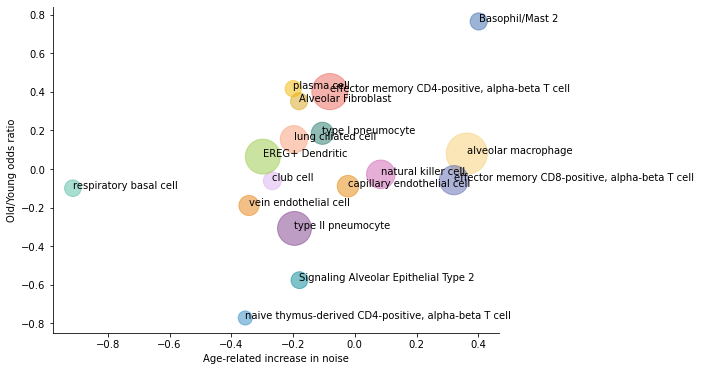

In [135]:
plot_noise_vs_enrichment(diff, enrichment, method='scallop_noise')
plt.savefig('../../output/figs/raredon/noise_vs_enrichment.svg')
plt.savefig('../../output/figs/raredon/noise_vs_enrichment.png', dpi=400)

In [139]:
# Statistically significant
enrichment[enrichment['p.value'] < 0.01].loc[:, ['odds_ratio', 'p.value']].sort_values('odds_ratio', ascending=False)

,odds_ratio,p.value
Cell_type,,
Basophil/Mast 2,5.818336,7.385054e-20
plasma cell,2.606996,1.901017e-06
"effector memory CD4-positive, alpha-beta T cell",2.518635,1.096424e-67
Alveolar Fibroblast,2.244912,1.609580e-06
bronchial smooth muscle cell,2.108756,7.158894e-04
type I pneumocyte,1.531519,6.802977e-06
lung ciliated cell,1.426349,3.996605e-07
alveolar macrophage,1.201708,3.609547e-05
EREG+ Dendritic,1.159152,4.695447e-03


# Noise

In [30]:
# 1) euc_dist and 4) man_dist:
adata = tn.distance_to_celltype_mean(adata, batch='donor')

  0%|                                                     | 0/9 [00:00<?, ?it/s]/media/amon/2TB-HD/Olga/Aging_and_transcriptional_noise/tools/transcriptional_noise.py:151: RuntimeWarning: Mean of empty slice.
  mean_expr.loc[:, f'{b}_{ct}'] = adata[(adata.obs[batch] == b) & (adata.obs['cell_type'] == ct), :].X.toarray().mean(axis=0)
/home/amon/anaconda3/lib/python3.7/site-packages/numpy/core/_methods.py:181: RuntimeWarning: invalid value encountered in true_divide
  ret, rcount, out=ret, casting='unsafe', subok=False)
100%|█████████████████████████████████████████████| 9/9 [06:39<00:00, 44.42s/it]


In [34]:
# 2) euc_dist_tissue_invar:
adata = tn.enge_euclidean_dist(adata)

100%|████████████████████████████████████| 15852/15852 [02:35<00:00, 102.11it/s]


In [36]:
# 3) euc_dist_invar:
adata = tn.distance_to_celltype_mean_invariant(adata, batch='donor')

  0%|                                                     | 0/9 [00:00<?, ?it/s]/media/amon/2TB-HD/Olga/Aging_and_transcriptional_noise/tools/transcriptional_noise.py:358: RuntimeWarning: Mean of empty slice.
  mean_expr.loc[:, f'{b}_{ct}'] = adata[(adata.obs[batch] == b) & (adata.obs['cell_type'] == ct), lvgs].X.toarray().mean(axis=0)
100%|█████████████████████████████████████████████| 9/9 [07:55<00:00, 52.83s/it]


In [38]:
# 5) cor_dist_median:
adata = tn.hernando_herraez(adata, batch='donor')

  0%|                                                     | 0/9 [00:00<?, ?it/s]/home/amon/anaconda3/lib/python3.7/site-packages/numpy/core/fromnumeric.py:3420: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
 11%|█████                                        | 1/9 [00:04<00:39,  4.98s/it]/home/amon/anaconda3/lib/python3.7/site-packages/scipy/spatial/distance.py:714: RuntimeWarning: invalid value encountered in float_scalars
  dist = 1.0 - uv / np.sqrt(uu * vv)
100%|█████████████████████████████████████████████| 9/9 [02:11<00:00, 14.56s/it]


In [ ]:
# adata.obs['cell_type_save'] = adata.obs['cell_type']
# adata.obs['cell_type'] = adata.obs['leiden']

In [ ]:
# adata.obs['cell_type'] = adata.obs['cell_type_save']

In [3]:
adata.obs['condition'] = adata.obs['age']
adata.obs['donor'] = adata.obs['batch']

In [4]:
# 6: Scallop
adata = tn.scallop_pipeline(adata)

Trying to set attribute `.obs` of view, copying.

2021-10-01 17:12:14,027 - scallop / root - INFO - Obtaining score with following parameters: 
 Resolution: 0.1
 Fraction of cells: 0.8
 Number of trials: 30
 Score type: freq
Clustering type: leiden, seed: None

2021-10-01 17:12:14,029 - scallop / root - INFO - The Bootstrap object did not exist and will been created.

2021-10-01 17:12:14,029 - scallop / root - INFO - Calculating the bootstrap matrix.

2021-10-01 17:12:14,055 - scallop / root - INFO - Obtaining bootstrap matrix. 1 processes are used at once.
100%|███████████████████████████████████████████| 30/30 [00:00<00:00, 60.97it/s]

2021-10-01 17:12:14,551 - scallop / root - INFO - Renaming identities.

2021-10-01 17:12:14,562 - scallop / root - INFO - Applying mapping of equivalent unknowns with threshold 0.5.

2021-10-01 17:12:14,563 - scallop / root - INFO - Calculating freqScore.

2021-10-01 17:12:14,586 - scallop / root - INFO - Obtaining score with following parameters: 
 Re

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'batch' as categorical
/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'sex' as categorical
/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused cat

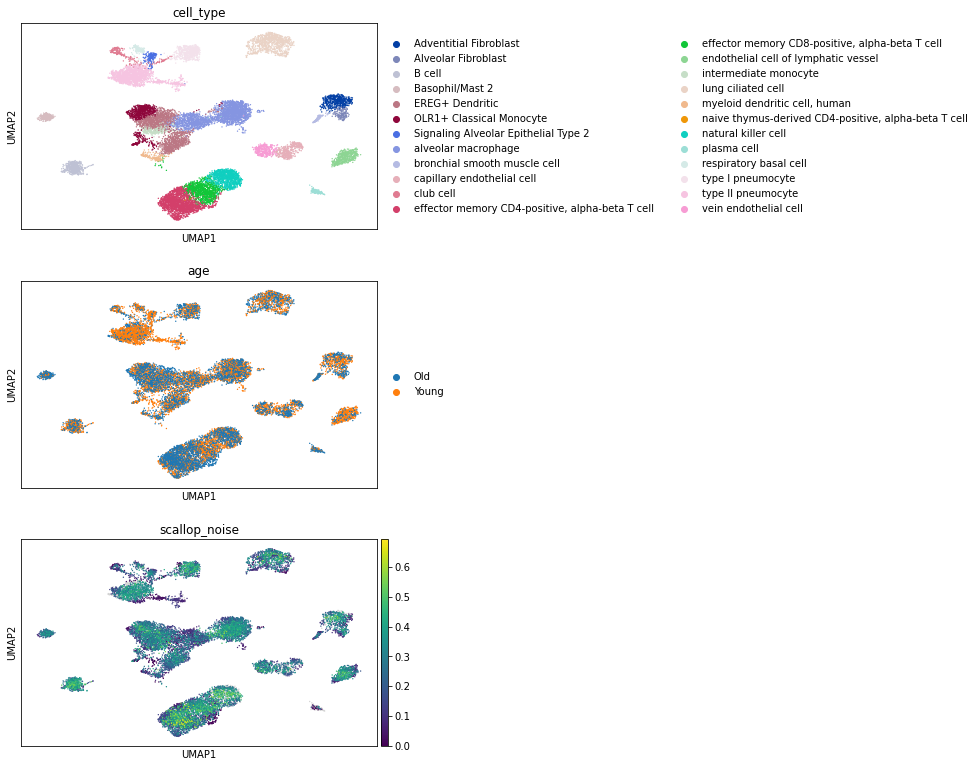

In [114]:
sc.pl.umap(adata, color=['cell_type', 'age', 'scallop_noise'], ncols=1)

In [47]:
# adata.obs.to_csv('../../output/tables/raredon/obs_data_frame.csv')

In [40]:
# 7) GCL
gcl = tn.gcl_per_cell_type_and_batch(adata, num_divisions=30)

100%|███████████████████████████████████████████| 24/24 [16:07<00:00, 40.33s/it]


In [41]:
gcl.to_csv('../../output/tables/raredon/raredon_gcl.csv')

In [13]:
obs

,batch,sex,age,leiden,cell_type,age_number,condition,donor,cor_dist,euc_dist,man_dist,euc_dist_tissue_invar,cor_dist_invar,euc_dist_invar,man_dist_invar,cor_dist_median,scallop_noise
x,,,,,,,,,,,,,,,,,
HC1__AAACCTGTCTCCGGTT-GSM3926545,GSM3926545,female,Old,17,intermediate monocyte,76.0,Old,GSM3926545,0.173949,37.751389,2610.964844,11.105499,0.516122,10.516388,232.014359,0.093187,0.227166
HC1__AAGTCTGAGCCACGCT-GSM3926545,GSM3926545,female,Old,17,intermediate monocyte,76.0,Old,GSM3926545,0.185692,38.591461,2656.135254,11.818871,0.497485,10.970557,235.781769,0.234765,0.111765
HC1__ACATACGCATACGCCG-GSM3926545,GSM3926545,female,Old,17,intermediate monocyte,76.0,Old,GSM3926545,0.150967,35.330845,2507.947021,11.039413,0.455788,10.202843,229.227478,0.195373,0.181404
HC1__ACGAGGAAGAGTACAT-GSM3926545,GSM3926545,female,Old,17,intermediate monocyte,76.0,Old,GSM3926545,0.233201,43.982563,2972.271484,12.034084,0.574251,11.457968,241.633881,0.273605,0.261298
HC1__ACTTACTCATAAAGGT-GSM3926545,GSM3926545,female,Old,17,intermediate monocyte,76.0,Old,GSM3926545,0.187018,39.424809,2759.351318,12.330519,0.457719,11.294430,244.981155,0.264442,0.063555
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
222C_AACGTTGCACCAGATT-GSM4050112,GSM4050112,male,Old,18,Basophil/Mast 2,65.0,Old,GSM4050112,0.360378,52.084141,2673.838135,11.303268,0.711862,10.615276,134.621979,0.257290,0.305140
222C_AGCAGCCGTACATGTC-GSM4050112,GSM4050112,male,Old,18,Basophil/Mast 2,65.0,Old,GSM4050112,0.361244,51.633480,2641.072754,13.098059,0.737885,12.599741,156.450531,0.221675,0.281996
222C_CGATGGCAGGCGATAC-GSM4050112,GSM4050112,male,Old,18,Basophil/Mast 2,65.0,Old,GSM4050112,0.268774,45.208698,2664.022705,11.011326,0.710877,10.688751,163.405441,0.144740,0.201135


In [23]:
adata.shape

(15852, 46204)

In [24]:
obs.shape

(15852, 17)

In [25]:
adata.obs = obs

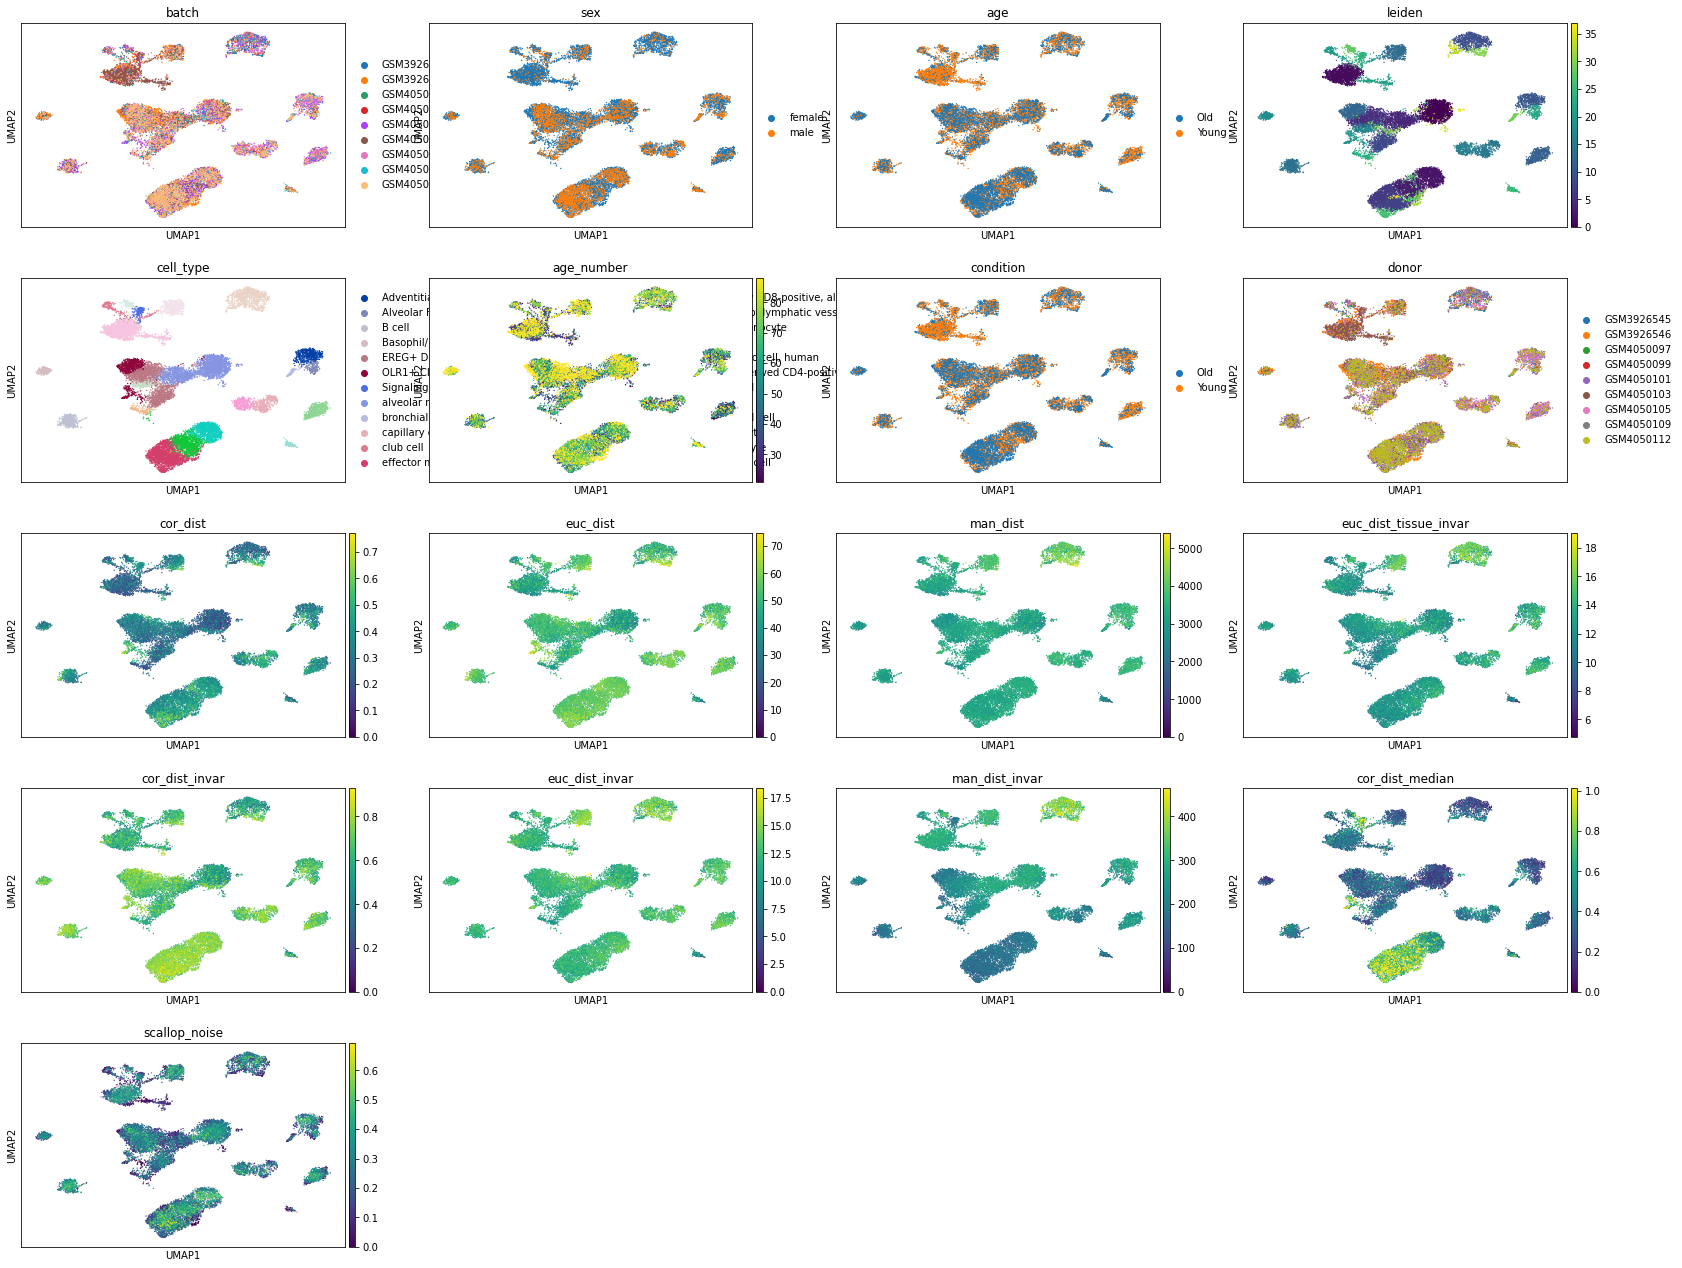

In [116]:
sc.pl.umap(adata, color=[obs for obs in adata.obs])

# Compute standardized transcriptional noise

In [ ]:
gcl = pd.read_csv('../../output/tables/raredon/raredon_gcl.csv', index_col=0)

In [ ]:
gcl.isnull().sum()

GCL          1770
age          1770
cell_type    1770
batch        1770
dtype: int64

In [ ]:
obs = pd.read_csv('../../output/tables/raredon/obs_data_frame.csv', index_col=0)

In [ ]:
adata.obs = obs

In [ ]:
def scale(df, scaling):
    df_scaled = df.copy()
    if scaling == 'minmax':
        min_max_scaler = MinMaxScaler()
        df_scaled[methods] = min_max_scaler.fit_transform(df[methods])
    elif scaling == 'robust':
        robust_scaler = RobustScaler()
        df_scaled[methods] = robust_scaler.fit_transform(df[methods])
    return df_scaled

def scale_gcl(df, scaling):
    df_scaled = df.copy()
    if scaling == 'minmax':
        min_max_scaler = MinMaxScaler()
        df_scaled.loc[:, 'GCL'] = min_max_scaler.fit_transform(df.loc[:, ['GCL']])
    elif scaling == 'robust':
        robust_scaler = RobustScaler()
        df_scaled.loc[:,'GCL'] = robust_scaler.fit_transform(df.loc[:, ['GCL']])
    return df_scaled

In [ ]:
methods = ['euc_dist', 'man_dist', 'euc_dist_tissue_invar', 'euc_dist_invar', 'cor_dist_median', 'scallop_noise']

In [ ]:
noise = adata.obs[['euc_dist', 'man_dist', 'euc_dist_tissue_invar', 'euc_dist_invar', 'cor_dist_median', 'scallop_noise']]
noise_rob = scale(noise, scaling='robust')

In [ ]:
gcl_rob = scale_gcl(gcl, scaling='robust')
gcl_rob['smoke_status'] = gcl_rob['age']

In [ ]:
noise_rob.loc[:, 'cell_type'] = adata.obs.loc[noise_rob.index, 'cell_type']
noise_rob.loc[:, 'age'] = adata.obs.loc[noise_rob.index, 'age']

In [ ]:
def get_age_related_difference(df):
    output = pd.DataFrame(index=set(df.cell_type), columns=methods)
    for method in methods:
        for ct in set(df.cell_type):
            young = df.loc[(df.age=='Young') & (df.cell_type==ct), method].mean()
            old = df.loc[(df.age=='Old') & (df.cell_type==ct), method].mean()
            output.loc[ct, method] = old - young
            
    return output

def get_age_related_difference_gcl(df): 
    # GCL measures coordination between genes. We compute noise as 1-GCL
    output = pd.DataFrame(index=set(df.cell_type), columns=['GCL'])
    for ct in set(df.cell_type):
        young = df.loc[(df.age=='Young') & (df.cell_type==ct), 'GCL'].mean()
        old = df.loc[(df.age=='Old') & (df.cell_type==ct), 'GCL'].mean()
        output.loc[ct, 'GCL'] = young - old # 1-GCL
    return output

In [ ]:
diff = get_age_related_difference(noise_rob).astype(float)

In [ ]:
diff

,euc_dist,man_dist,euc_dist_tissue_invar,euc_dist_invar,cor_dist_median,scallop_noise
type II pneumocyte,0.005503,0.104116,0.318518,0.198641,0.067437,NaN
intermediate monocyte,-0.007840,0.239897,0.068393,0.069533,0.126877,-0.180528
Basophil/Mast 2,0.071241,1.365554,0.428634,0.694227,-0.118750,0.362888
plasma cell,-0.393213,-0.414965,-0.899820,-0.612005,-0.028637,NaN
OLR1+ Classical Monocyte,-0.226542,-0.229186,-0.012263,-0.018081,-0.322138,0.401322
Adventitial Fibroblast,-0.265181,0.079950,0.049426,-0.110625,0.094226,NaN
vein endothelial cell,-0.190113,0.108765,-0.056325,-0.067651,-0.063867,-0.021890
Signaling Alveolar Epithelial Type 2,0.027315,0.491500,0.423275,0.224633,-0.391695,-0.267195
bronchial smooth muscle cell,0.121559,1.252977,0.151638,0.649855,-0.132853,-0.080495
"myeloid dendritic cell, human",-0.082009,0.040865,-0.179333,-0.117943,-0.011545,0.321192


In [129]:
def fill_missing_ct_and_sort(df, ct_order):
    add_indices = pd.Index(set(ct_order)).difference(df.index)
    add_df = pd.DataFrame(index=add_indices, columns=df.columns).fillna(np.nan)
    df = pd.concat([df, add_df])
    return df.loc[ct_order, :]

In [130]:
ct_order = list(set(adata.obs['cell_type']))
diff = fill_missing_ct_and_sort(diff, ct_order)
diff['GCL'] = fill_missing_ct_and_sort(get_smoking_related_difference_gcl(gcl_rob).astype(float), ct_order)

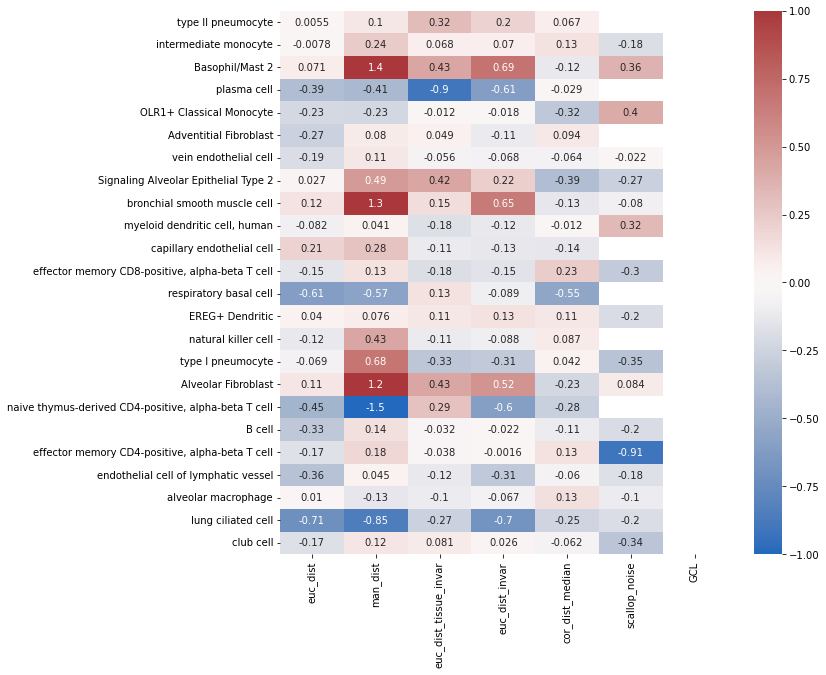

In [131]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 10))
sns.heatmap(diff, center=0, cmap='vlag', robust=True, annot=True, vmax=1, vmin=-1)
plt.savefig('../../output/figs/raredon/heatmap_diff_noise_per_subcluster_ident.svg')
plt.savefig('../../output/figs/raredon/heatmap_diff_noise_per_subcluster_ident.png', dpi=400)

In [132]:
ct2keep = diff[diff.isnull().sum(axis=1)/len(diff.index) <= 0.25].index.tolist()
diff_inputed = diff.loc[ct2keep, :].transpose().fillna(diff.loc[ct2keep, :].transpose().mean(axis=0), axis=0).transpose()

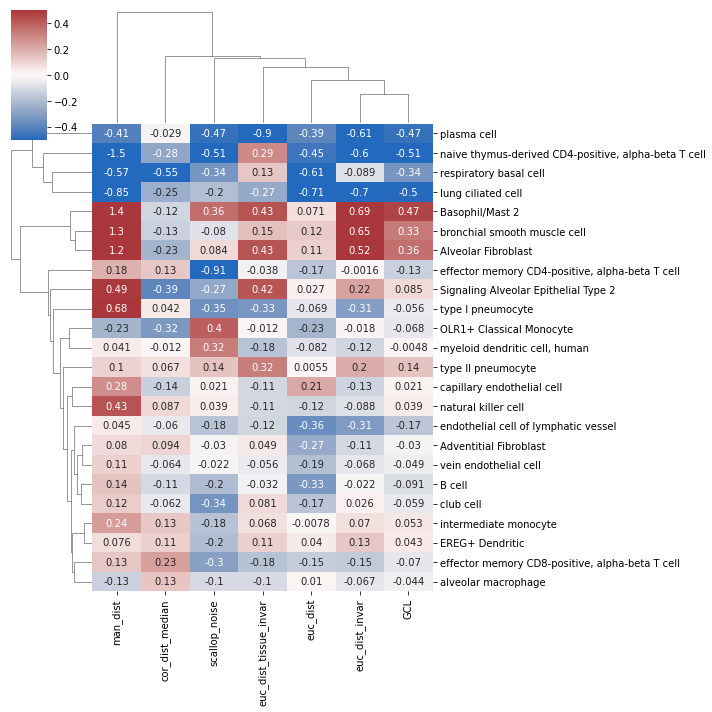

In [133]:
sns.clustermap(diff_inputed, cmap='vlag', center=0, annot=True, vmin=-0.5, vmax=0.5)
plt.savefig('../../output/figs/raredon/clustermap_diff_noise_per_subcluster_ident.svg')
plt.savefig('../../output/figs/raredon/clustermap_diff_noise_per_subcluster_ident.png', dpi=400)